# 3.0 — Integración temporal del panel (Fase A)

Une en el tiempo las seis capas a nivel **municipio** (Hermosillo) en un panel
mensual y uno semanal:

| Capa | Fuente | Notebook |
|------|--------|----------|
| Temperatura | SMN/CONAGUA (mensual) | 2.0 |
| Calor diario | Open-Meteo (reanálisis) | 2.1 |
| Sequía | Monitor de Sequía CONAGUA | 2.2 |
| Marginación | CONAPO (censos 2015 y 2020) | 2.3 |
| Calidad del aire | RUOA-UNAM, estación ERNO | 2.4 |
| Casos de IRA | Salud Sonora (SUIVE) | 2.5 |

El análisis espacial intra-urbano se hace por **colonia** en
`3.6-analisis-marginacion-urbana.ipynb`; lo que queda abierto es la
residencia del paciente (los casos son por unidad que reporta).

## Entradas
- `data/processed/*.parquet` y `data/processed/aire/*.csv` de los notebooks `02_procesamiento/`
  (correr 2.0 → 2.5 antes que este notebook).

## Salidas
- `data/processed/panel_hermosillo.parquet` — panel mensual completo.
- `data/processed/panel_hermosillo_semanal.parquet` — panel semanal completo.
- `data/processed/panel_eda.parquet` y `panel_eda_semanal.parquet` — fecha + variables EDA, para los notebooks 3.1–3.5.

Descripción de cada columna: `docs/docs/catalogo_datos_panel.md`.

`build_panel_monthly()` y `build_panel_weekly()` de `panel.py` leen las tablas
limpias de los notebooks `2.x`, las unen por fecha, crean las columnas de
banderas (`anio_atipico`, ola de calor × sequía) y guardan los `.parquet`.

In [16]:
from pathlib import Path
import sys

ROOT_DIR = Path.cwd().parent.parent  # notebooks/<seccion>/ -> raiz del proyecto
if str(ROOT_DIR) not in sys.path:
    sys.path.append(str(ROOT_DIR))

from sonora_health_climate_eda.config import PROCESSED_DATA_DIR
from sonora_health_climate_eda.panel import (
    build_panel_monthly,
    build_panel_weekly,
    air_quality_analysis,
)

panel_mensual = build_panel_monthly()
panel_semanal = build_panel_weekly()

panel_mensual.head()


2026-11-15 23:27:00.502 -07:00 | SUCCESS  | sonora_health_climate_eda.panel:build_panel_monthly:626 - Panel guardado en /Users/benancio/Documents/sonora-health-climate-eda/data/processed/panel_hermosillo.parquet (72 meses).
2026-11-15 23:27:00.524 -07:00 | SUCCESS  | sonora_health_climate_eda.panel:build_panel_weekly:691 - Panel semanal guardado en /Users/benancio/Documents/sonora-health-climate-eda/data/processed/panel_hermosillo_semanal.parquet (313 semanas).


,fecha_mes,temp_media_c,temp_max_media_c,temp_min_media_c,pm25_ugm3,pm25_max_diario_ugm3,pm25_dias_excede_nom,pm25_categoria_peor_dia,pm25_dias_aceptable_o_peor,pm25_dias_validos,...,n_olas_calor_p95,n_olas_calor_humedo,mes_calor_extremo,mes_sequia,mes_extremo_conjunto,mes_ola_calor,mes_ola_calor_p95,mes_ola_calor_p95_y_sequia,mes_calor_humedo,anio_atipico
0,2015-01-01,18.766667,26.066667,11.433333,NaN,NaN,NaN,NaN,NaN,8,...,0,0,False,False,False,False,False,False,False,False
1,2015-02-01,22.000000,29.500000,14.466667,8.35,11.69,0.0,Buena,0.0,28,...,0,0,False,False,False,False,False,False,False,False
2,2015-03-01,24.100000,31.433333,16.733333,7.58,11.23,0.0,Buena,0.0,30,...,0,0,False,False,False,True,False,False,False,False
3,2015-04-01,24.966667,32.766667,17.100000,8.44,11.46,0.0,Buena,0.0,30,...,0,0,False,False,False,True,False,False,False,False
4,2015-05-01,26.066667,33.766667,18.366667,8.41,15.78,0.0,Buena,0.0,31,...,0,1,False,False,False,True,False,False,True,False


In [2]:
panel_semanal.head()


,fecha_semana,pm25_ugm3,pm25_max_diario_ugm3,pm25_dias_excede_nom,pm25_categoria_peor_dia,pm25_dias_aceptable_o_peor,pm25_dias_validos,pm25_interpolado,pm10_ugm3,pm10_max_diario_ugm3,...,n_olas_calor_p95,n_olas_calor_humedo,semana_calor_extremo,semana_sequia,semana_extremo_conjunto,semana_ola_calor,semana_ola_calor_p95,semana_ola_calor_p95_y_sequia,semana_calor_humedo,anio_atipico
0,2015-01-04,NaN,NaN,NaN,NaN,NaN,0,False,60.53,124.80,...,0,0,False,False,False,False,False,False,False,False
1,2015-01-11,NaN,NaN,NaN,NaN,NaN,0,False,54.11,104.42,...,0,0,False,False,False,False,False,False,False,False
2,2015-01-18,NaN,NaN,NaN,NaN,NaN,1,False,57.04,65.80,...,0,0,False,False,False,False,False,False,False,False
3,2015-01-25,7.10,9.11,0.0,Buena,0.0,7,False,24.00,36.58,...,0,0,False,False,False,False,False,False,False,False
4,2015-02-01,9.61,11.39,0.0,Buena,0.0,7,False,34.86,48.57,...,0,0,False,False,False,False,False,False,False,False


In [3]:
panel_semanal.shape  # se esperan 313 semanas (2015-2020)


(313, 62)

In [ ]:
panel_semanal.info()

<class 'pandas.DataFrame'>
RangeIndex: 313 entries, 0 to 312
Data columns (total 62 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   fecha_semana                   313 non-null    datetime64[us]
 1   pm25_ugm3                      171 non-null    float64       
 2   pm25_max_diario_ugm3           167 non-null    float64       
 3   pm25_dias_excede_nom           167 non-null    float64       
 4   pm25_categoria_peor_dia        167 non-null    str           
 5   pm25_dias_aceptable_o_peor     167 non-null    float64       
 6   pm25_dias_validos              313 non-null    int64         
 7   pm25_interpolado               313 non-null    bool          
 8   pm10_ugm3                      286 non-null    float64       
 9   pm10_max_diario_ugm3           281 non-null    float64       
 10  pm10_dias_excede_nom           281 non-null    float64       
 11  pm10_categoria_peor_dia       

## Checklist de preparación para la EDA

Se preparan **los dos paneles**:

| Panel | Periodo | Clima | Casos |
|-------|---------|-------|-------|
| Mensual (`panel_mensual`) | 72 meses | Tmed/Tmax/Tmin del SMN + cálculos de Open-Meteo | `casos_ira` (suma del mes) |
| Semanal (`panel_semanal`) | 313 semanas epidemiológicas | Solo Open-Meteo | `casos_ira_total` (casos de la semana) |

Marcar `[x]` conforme se complete cada punto. Debajo de cada sección hay una
celda de código vacía para agregar lo necesario.

### 1. Revisar los paneles

- [ ] Mensual: 72 meses (ene-2015 a dic-2020), sin fechas repetidas.
- [ ] Semanal: 313 semanas (2015-01-04 a 2020-12-27), sin fechas repetidas.
- [ ] Porcentaje de faltantes por columna en los dos, para ver qué capas tienen huecos
  (en el semanal hay una semana sin sequía).

**Panel semanal** — periodos, rango de fechas, duplicados y % de faltantes por columna.

In [5]:
n_semanas = len(panel_semanal)
rango_semanas = (panel_semanal['fecha_semana'].min(), panel_semanal['fecha_semana'].max())
duplicados_semana = panel_semanal['fecha_semana'].duplicated().sum()

print(f"Total de periodos (filas): {n_semanas}")
print(f"Rango de fechas: {rango_semanas[0]} a {rango_semanas[1]}")
print(f"Fechas repetidas (duplicados): {duplicados_semana}")

faltantes_semana = panel_semanal.isna().mean() * 100
print("\nPorcentaje de valores faltantes por columna (Semanal):")
print(faltantes_semana[faltantes_semana > 0].sort_values(ascending=False))


Total de periodos (filas): 313
Rango de fechas: 2015-01-04 00:00:00 a 2020-12-27 00:00:00
Fechas repetidas (duplicados): 0

Porcentaje de valores faltantes por columna (Semanal):
pm25_dias_excede_nom             46.645367
pm25_categoria_peor_dia          46.645367
pm25_dias_aceptable_o_peor       46.645367
pm25_max_diario_ugm3             46.645367
pm25_ugm3                        45.367412
pm10_o3_dias_aceptable_o_peor    15.654952
pm10_o3_categoria_peor_dia       15.654952
o3_max8h_max_ppb                 15.015974
o3_dias_aceptable_o_peor         15.015974
o3_categoria_peor_dia            15.015974
o3_dias_excede_nom               15.015974
o3_ppb                           10.862620
o3_max8h_ppb                     10.862620
pm10_dias_aceptable_o_peor       10.223642
pm10_categoria_peor_dia          10.223642
pm10_dias_excede_nom             10.223642
pm10_max_diario_ugm3             10.223642
pm10_ugm3                         8.626198
severidad_sequia                  0.319489
cate

**Panel mensual** — lo mismo, con los 72 meses.

In [6]:
n_meses = len(panel_mensual)
rango_meses = (panel_mensual['fecha_mes'].min(), panel_mensual['fecha_mes'].max())
duplicados_mes = panel_mensual['fecha_mes'].duplicated().sum()

print(f"Total de periodos (filas): {n_meses}")
print(f"Rango de fechas: {rango_meses[0]} a {rango_meses[1]}")
print(f"Fechas repetidas (duplicados): {duplicados_mes}")

faltantes_mes = panel_mensual.isna().mean() * 100
print("\nPorcentaje de valores faltantes por columna (Mensual):")
print(faltantes_mes[faltantes_mes > 0].sort_values(ascending=False))


Total de periodos (filas): 72
Rango de fechas: 2015-01-01 00:00:00 a 2020-12-01 00:00:00
Fechas repetidas (duplicados): 0

Porcentaje de valores faltantes por columna (Mensual):
pm25_ugm3                        47.222222
pm25_max_diario_ugm3             47.222222
pm25_dias_excede_nom             47.222222
pm25_categoria_peor_dia          47.222222
pm25_dias_aceptable_o_peor       47.222222
pm10_o3_dias_aceptable_o_peor    19.444444
pm10_o3_categoria_peor_dia       19.444444
o3_dias_aceptable_o_peor         16.666667
o3_categoria_peor_dia            16.666667
o3_dias_excede_nom               16.666667
o3_max8h_max_ppb                 16.666667
o3_ppb                           15.277778
o3_max8h_ppb                     15.277778
pm10_dias_excede_nom             12.500000
pm10_dias_aceptable_o_peor       12.500000
pm10_categoria_peor_dia          12.500000
pm10_max_diario_ugm3             12.500000
pm10_ugm3                        11.111111
temp_max_media_c                  4.166667
temp_

### 2. Nombre de la columna de casos

En el panel **mensual**, `casos_ira_total` **no es el total del mes**: es el
promedio de casos por semana (`casos_ira / n_semanas`). El catálogo la llama
`casos_ira_por_semana`. En el **semanal**, `casos_ira_total` sí son los casos de
la semana y no se cambia.

- [ ] Mensual: renombrar `casos_ira_total` → `casos_ira_por_semana`.
- [ ] Mensual: comprobar que `casos_ira / n_semanas` da lo mismo.
- [ ] Comprobar que la suma de casos coincide entre los dos paneles.

In [7]:
# Renombrar en el mensual; el if evita error si la celda se corre dos veces
if 'casos_ira_total' in panel_mensual.columns:
    panel_mensual = panel_mensual.rename(columns={'casos_ira_total': 'casos_ira_por_semana'})
    print("✓ Columna renombrada: 'casos_ira_total' -> 'casos_ira_por_semana' en panel_mensual.")
else:
    print("La columna 'casos_ira_total' ya no existe o ya fue renombrada.")

# Comprobar que casos_ira_por_semana == casos_ira / n_semanas
if {'casos_ira', 'n_semanas', 'casos_ira_por_semana'}.issubset(panel_mensual.columns):
    calculado = panel_mensual['casos_ira'] / panel_mensual['n_semanas']
    diferencia = (panel_mensual['casos_ira_por_semana'] - calculado).abs().max()
    print(f"Diferencia maxima vs. 'casos_ira'/'n_semanas': {diferencia}")
    if diferencia < 1e-5:  # margen por redondeo de decimales
        print("✓ 'casos_ira_por_semana' equivale al promedio por semana.")
    else:
        print("⚠ Hay discrepancias. Revisa los valores o nombres de las columnas.")
else:
    print("Faltan columnas ('casos_ira', 'n_semanas') para la comprobacion.")

# La suma total de casos debe coincidir entre los dos paneles
print("\n--- Comparación de la suma total de casos ---")
total_semanal = panel_semanal['casos_ira_total'].sum()
print(f"Suma total (semanal): {total_semanal:,.2f}")

if 'n_semanas' in panel_mensual.columns and 'casos_ira_por_semana' in panel_mensual.columns:
    # promedio por semana × n_semanas = casos del mes
    total_mensual = (panel_mensual['casos_ira_por_semana'] * panel_mensual['n_semanas']).sum()
    print(f"Suma total calculada (mensual): {total_mensual:,.2f}")
    print(f"Diferencia absoluta entre paneles: {abs(total_semanal - total_mensual):,.2f}")
elif 'casos_ira' in panel_mensual.columns:
    total_mensual = panel_mensual['casos_ira'].sum()
    print(f"Suma total (mensual, 'casos_ira'): {total_mensual:,.2f}")


✓ Columna renombrada exitosamente: 'casos_ira_total' -> 'casos_ira_por_semana' en panel_mensual.
Diferencia máxima entre 'casos_ira_por_semana' y ('casos_ira' / 'n_semanas'): 0.0
✓ Comprobación exitosa: 'casos_ira_por_semana' equivale exactamente al promedio por semana.

--- Comparación de la suma total de casos ---
Suma total (panel_semanal['casos_ira_total']): 1,129,099.00
Suma total calculada (panel_mensual ['casos_ira_por_semana' * 'n_semanas']): 1,129,099.00
Diferencia absoluta entre paneles: 0.00


### 3. Lista de variables para la EDA

| Grupo | Mensual | Semanal |
|-------|---------|---------|
| Respuesta | `casos_ira`, `casos_ira_por_semana`, `n_semanas` | `casos_ira_total` |
| Calor | `tmax_media_mes`, `dias_ola_calor_p95`, `humedad_rel_media` (Open-Meteo; comparación: `temp_max_media_c` del SMN) | `tmax_media_sem`, `dias_ola_calor_p95`, `humedad_rel_media` |
| Sequía | `severidad_sequia` | `severidad_sequia` |
| Aire | `pm10_ugm3`, `o3_max8h_ppb` | `pm10_ugm3`, `o3_max8h_ppb` |
| Contexto | `IM` | `IM` |
| Banderas | `mes_ola_calor_p95_y_sequia`, `anio_atipico` | `semana_ola_calor_p95_y_sequia`, `anio_atipico` |

- [ ] Definir `VARIABLES_EDA` (mensual) y `VARIABLES_EDA_SEMANAL`.
- [ ] Revisar que todas existan en su panel.

In [8]:
VARIABLES_EDA = {
    "respuesta": ["casos_ira", "casos_ira_por_semana", "n_semanas"],
    "calor": ["tmax_media_mes", "dias_ola_calor_p95", "humedad_rel_media", "temp_max_media_c"],
    "sequia": ["severidad_sequia"],
    "aire": ["pm10_ugm3", "o3_max8h_ppb"],
    "contexto": ["IM"],
    "banderas": ["mes_ola_calor_p95_y_sequia", "anio_atipico"]
}

# sin temp_max_media_c: el SMN solo tiene datos mensuales
VARIABLES_EDA_SEMANAL = {
    "respuesta": ["casos_ira_total"],
    "calor": ["tmax_media_sem", "dias_ola_calor_p95", "humedad_rel_media"],
    "sequia": ["severidad_sequia"],
    "aire": ["pm10_ugm3", "o3_max8h_ppb"],
    "contexto": ["IM"],
    "banderas": ["semana_ola_calor_p95_y_sequia", "anio_atipico"]
}

def verificar_variables(df, dic_vars, nombre_panel):
    print("=" * 50)
    print(f"VERIFICANDO VARIABLES EN: {nombre_panel}")
    print("=" * 50)

    faltantes_totales = []
    for grupo, lista_vars in dic_vars.items():
        faltantes = [v for v in lista_vars if v not in df.columns]
        if faltantes:
            print(f" Grupo '{grupo}': faltan las columnas -> {faltantes}")
            faltantes_totales.extend(faltantes)
        else:
            print(f"✓ Grupo '{grupo}': todas las variables ({len(lista_vars)}) estan presentes.")

    print("-" * 50)
    if not faltantes_totales:
        print(f"¡Excelente! Todas las variables de {nombre_panel} existen en el DataFrame.\n")
    else:
        print(f"⚠ Alerta: {len(faltantes_totales)} columnas faltantes en {nombre_panel}.\n")

verificar_variables(panel_mensual, VARIABLES_EDA, "panel_mensual")
verificar_variables(panel_semanal, VARIABLES_EDA_SEMANAL, "panel_semanal")


VERIFICANDO VARIABLES EN: panel_mensual
✓ Grupo 'respuesta': Todas las variables (3) están presentes.
✓ Grupo 'calor': Todas las variables (4) están presentes.
✓ Grupo 'sequia': Todas las variables (1) están presentes.
✓ Grupo 'aire': Todas las variables (2) están presentes.
✓ Grupo 'contexto': Todas las variables (1) están presentes.
✓ Grupo 'banderas': Todas las variables (2) están presentes.
--------------------------------------------------
¡Excelente! Todas las variables de panel_mensual existen en el DataFrame.

VERIFICANDO VARIABLES EN: panel_semanal
✓ Grupo 'respuesta': Todas las variables (1) están presentes.
✓ Grupo 'calor': Todas las variables (3) están presentes.
✓ Grupo 'sequia': Todas las variables (1) están presentes.
✓ Grupo 'aire': Todas las variables (2) están presentes.
✓ Grupo 'contexto': Todas las variables (1) están presentes.
✓ Grupo 'banderas': Todas las variables (2) están presentes.
--------------------------------------------------
¡Excelente! Todas las varia

### 4. Calidad del aire

PM2.5 tiene datos en solo 38 de 72 meses (171 de 313 semanas); PM10 y O3 en
60–64 meses (279–286 semanas). Rellenar huecos largos inventaría datos.

- [ ] Cobertura de PM2.5, PM10 y O3 en los dos paneles, para justificar dejar fuera PM2.5.
- [ ] Cuántos periodos de PM10 y O3 vienen interpolados (`*_interpolado`).

In [9]:
if 'panel_semanal' in locals():
    air_quality_analysis(panel_semanal, "panel_semanal")

if 'panel_mensual' in locals():
    air_quality_analysis(panel_mensual, "panel_mensual")


ANÁLISIS DE CALIDAD DEL AIRE: panel_semanal
Total de periodos en panel_semanal: 313

--- 1. COBERTURA DE DATOS (Valores válidos / No nulos) ---
[PM2.5]
  • pm25_ugm3: 171 / 313 (54.6%)
  • pm25_max_diario_ugm3: 167 / 313 (53.4%)
  • pm25_dias_excede_nom: 167 / 313 (53.4%)
  • pm25_categoria_peor_dia: 167 / 313 (53.4%)
  • pm25_dias_aceptable_o_peor: 167 / 313 (53.4%)
  • pm25_dias_validos: 313 / 313 (100.0%)
  • pm25_interpolado: 313 / 313 (100.0%)
[PM10]
  • pm10_ugm3: 286 / 313 (91.4%)
  • pm10_max_diario_ugm3: 281 / 313 (89.8%)
  • pm10_dias_excede_nom: 281 / 313 (89.8%)
  • pm10_categoria_peor_dia: 281 / 313 (89.8%)
  • pm10_dias_aceptable_o_peor: 281 / 313 (89.8%)
  • pm10_dias_validos: 313 / 313 (100.0%)
  • pm10_interpolado: 313 / 313 (100.0%)
  • pm10_o3_categoria_peor_dia: 264 / 313 (84.3%)
  • pm10_o3_dias_aceptable_o_peor: 264 / 313 (84.3%)
  • pm10_o3_dias_validos: 313 / 313 (100.0%)
[Ozono (O3)]
  • o3_ppb: 279 / 313 (89.1%)
  • o3_max8h_ppb: 279 / 313 (89.1%)
  • o3_max8h

### Decisión sobre calidad del aire
- **PM2.5: se excluye.** Solo ~53-55% de los datos son válidos en ambos
  paneles; rellenar huecos tan largos metería más datos inventados que
  reales.
- **PM10 y O3: se mantienen.** Tienen buena cobertura (~80-91%) y pocas
  interpolaciones.


### 5. Año 2020

Los casos caen ~70 % por la COVID-19 (cambió la notificación, no la enfermedad).
En el semanal, `anio_atipico` marca 53 semanas (la SE1 de 2020 empieza el 29-dic-2019).

- [ ] Crear `panel_base_mensual` y `panel_base_semanal` con 2015–2019 y comparar contra 2020.

In [12]:
# Separar los años normales (2015-2019) de 2020
panel_base_mensual = panel_mensual[~panel_mensual['anio_atipico']].copy()
panel_base_semanal = panel_semanal[~panel_semanal['anio_atipico']].copy()
panel_2020_mensual = panel_mensual[panel_mensual['anio_atipico']].copy()
panel_2020_semanal = panel_semanal[panel_semanal['anio_atipico']].copy()

print(f"✓ panel_base_mensual: {len(panel_base_mensual)} periodos (2015-2019)")
print(f"✓ panel_base_semanal: {len(panel_base_semanal)} periodos (2015-2019)")

print("\n" + "-" * 50)
print("COMPARACIÓN DE CASOS DE IRA (Promedios y Totales)")
print("-" * 50)

prom_base_sem = panel_base_semanal['casos_ira_total'].mean()
prom_2020_sem = panel_2020_semanal['casos_ira_total'].mean()

print("[Panel Semanal]")
print(f"  • Promedio semanal 2015-2019: {prom_base_sem:,.2f} casos")
print(f"  • Promedio semanal 2020:        {prom_2020_sem:,.2f} casos")

if prom_base_sem > 0:
    variacion_sem = ((prom_2020_sem - prom_base_sem) / prom_base_sem) * 100
    print(f"  • Variación en 2020:          {variacion_sem:.2f}%")

col_casos_mes = 'casos_ira' if 'casos_ira' in panel_mensual.columns else 'casos_ira_por_semana'
prom_base_mes = panel_base_mensual[col_casos_mes].mean()
prom_2020_mes = panel_2020_mensual[col_casos_mes].mean()

print(f"\n[Panel Mensual ({col_casos_mes})]")
print(f"  • Promedio mensual 2015-2019: {prom_base_mes:,.2f}")
print(f"  • Promedio mensual 2020:        {prom_2020_mes:,.2f}")

if prom_base_mes > 0:
    variacion_mes = ((prom_2020_mes - prom_base_mes) / prom_base_mes) * 100
    print(f"  • Variación en 2020:          {variacion_mes:.2f}%")


✓ panel_base_mensual creado: 60 periodos (2015-2019)
✓ panel_base_semanal creado: 260 periodos (2015-2019)

--------------------------------------------------
COMPARACIÓN DE CASOS DE IRA (Promedios y Totales)
--------------------------------------------------
[Panel Semanal]
  • Promedio semanal 2015–2019: 3,890.87 casos
  • Promedio semanal 2020:        2,216.47 casos
  • Variación en 2020:          -43.03%

[Panel Mensual (casos_ira)]
  • Promedio mensual 2015–2019: 16,928.12
  • Promedio mensual 2020:        9,451.00
  • Variación en 2020:          -44.17%


> **Por qué se excluye 2020:**
> El promedio de casos de IRA cayó ~43-44% en 2020 respecto a 2015-2019
> (semanal: de 3,890 a 2,216 casos; mensual: de 16,928 a 9,451). La caída
> no es que la gente se enfermara menos: cambió la notificación, hubo
> confinamiento y los servicios de salud se reordenaron por la pandemia.
> Dejarlo fuera de los paneles base evita que ese año raro arrastre
> todos los análisis.


### 6. Marginación

Con un solo municipio y un valor por censo, `IM` casi no cambia en el tiempo: no
puede explicar la variación de los casos. Se usa solo como contexto.

- [ ] Mostrar que `IM` casi no varía (valores únicos, rango) en los dos paneles.

ANÁLISIS DE VARIABILIDAD DE 'IM' EN AMBOS PANELES

--- PANEL MENSUAL ---
count    72.000000
mean     56.658468
std       2.919214
min      51.512968
25%      54.151610
50%      56.797587
75%      59.433783
max      60.443754
Name: IM, dtype: float64
Valores únicos (Mensual): [51.51296844 51.66458637 51.8015316  51.95314954 52.09987657 52.2514945
 52.39822154 52.54983947 52.70145741 52.84818444 52.99980237 53.14652941
 53.29814734 53.44976527 53.59160141 53.74321934 53.88994637 54.04156431
 54.18829134 54.33990928 54.49152721 54.63825424 54.78987218 54.93659921
 55.08821715 55.23983508 55.37678031 55.52839825 55.67512528 55.82674321
 55.97347025 56.12508818 56.27670612 56.42343315 56.57505108 56.72177812
 56.87339605 57.02501399 57.16195922 57.31357715 57.46030418 57.61192212
 57.75864915 57.91026709 58.06188502 58.20861205 58.36022999 58.50695702
 58.65857496 58.81019289 58.94713812 59.09875606 59.24548309 59.39710102
 59.54382806 59.69544599 59.84706393 59.99379096 60.14540889 60.2921

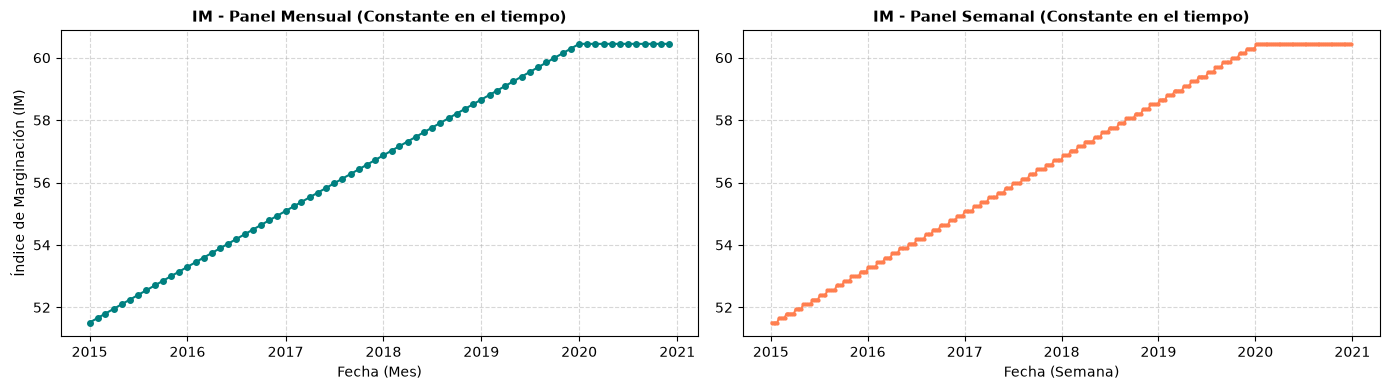

In [13]:
import matplotlib.pyplot as plt

print("ANÁLISIS DE VARIABILIDAD DE 'IM' EN AMBOS PANELES")

print("\n--- PANEL MENSUAL ---")
print(panel_mensual["IM"].describe())
print("Valores únicos (Mensual):", panel_mensual["IM"].unique())

print("\n--- PANEL SEMANAL ---")
print(panel_semanal["IM"].describe())
print("Valores únicos (Semanal):", panel_semanal["IM"].unique())

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

eje_x_mes = panel_mensual["fecha_mes"] if "fecha_mes" in panel_mensual.columns else panel_mensual.index
axes[0].plot(eje_x_mes, panel_mensual["IM"], marker="o", linestyle="-", color="teal", markersize=4)
axes[0].set_title("IM - Panel Mensual (Constante en el tiempo)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Fecha (Mes)", fontsize=10)
axes[0].set_ylabel("Índice de Marginación (IM)", fontsize=10)
axes[0].grid(True, linestyle="--", alpha=0.5)

eje_x_sem = panel_semanal["fecha_semana"] if "fecha_semana" in panel_semanal.columns else panel_semanal.index
axes[1].plot(eje_x_sem, panel_semanal["IM"], marker="o", linestyle="-", color="coral", markersize=2)
axes[1].set_title("IM - Panel Semanal (Constante en el tiempo)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Fecha (Semana)", fontsize=10)
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


> **Sobre el Índice de Marginación (`IM`):**
>
> `IM` no es plano, pero su "variación" es solo una línea recta suave de
> 2015 a 2020 — viene de una interpolación entre mediciones, no de cambios
> reales mes a mes. Como no fluctúa con las estaciones ni con las semanas
> raras, no puede explicar los cambios en casos de IRA. Se queda como
> **variable de contexto** (dónde estamos parados socialmente), no como
> predictor del modelo.


### 7. Guardar los paneles para la EDA

- [ ] Guardar `data/processed/panel_eda.parquet` con `fecha_mes` + `VARIABLES_EDA`.
- [ ] Guardar `data/processed/panel_eda_semanal.parquet` con `fecha_semana` + `VARIABLES_EDA_SEMANAL`.

In [17]:
cols_mensual_lista = [col for grupo in VARIABLES_EDA.values() for col in grupo]
cols_mensual_final = ["fecha_mes"] + list(dict.fromkeys(cols_mensual_lista))
cols_mensual_existentes = [c for c in cols_mensual_final if c in panel_mensual.columns]

ruta_mensual = PROCESSED_DATA_DIR / "panel_eda.parquet"
panel_mensual[cols_mensual_existentes].to_parquet(ruta_mensual, index=False)
print(f"✓ Guardado: {ruta_mensual} ({len(cols_mensual_existentes)} columnas)")

cols_semanal_lista = [col for grupo in VARIABLES_EDA_SEMANAL.values() for col in grupo]
cols_semanal_final = ["fecha_semana"] + list(dict.fromkeys(cols_semanal_lista))
cols_semanal_existentes = [c for c in cols_semanal_final if c in panel_semanal.columns]

ruta_semanal = PROCESSED_DATA_DIR / "panel_eda_semanal.parquet"
panel_semanal[cols_semanal_existentes].to_parquet(ruta_semanal, index=False)
print(f"✓ Guardado: {ruta_semanal} ({len(cols_semanal_existentes)} columnas)")


✓ Guardado exitosamente: /Users/benancio/Documents/sonora-health-climate-eda/data/processed/panel_eda.parquet (13 columnas)
✓ Guardado exitosamente: /Users/benancio/Documents/sonora-health-climate-eda/data/processed/panel_eda_semanal.parquet (11 columnas)


## Decisiones

| Decisión | Panel | Por qué | Fecha |
| :--- | :--- | :--- | :--- |
| **Renombrar `casos_ira_total` a `casos_ira_por_semana`** | Mensual | En el panel mensual representaba el promedio semanal (`casos_ira / n_semanas`). Renombrarlo evita subestimar o sobreestimar meses de 4 y 5 semanas. | Nov 2026 |
| **Exclusión de PM2.5** | Ambos (Semanal y Mensual) | Presenta una cobertura deficiente (~52%–54% de datos válidos). Rellenar huecos tan largos introduciría datos estimados (sesgo masivo). | Nov 2026 |
| **Retención de PM10 y O3** | Ambos (Semanal y Mensual) | Cuentan con una cobertura robusta (80%–91%) y muy baja interpolación, garantizando confiabilidad para el análisis. | Nov 2026 |
| **Tratamiento del Índice de Marginación (`IM`)** | Ambos | Muestra una progresión lineal suave por interpolación censal sin fluctuaciones rápidas; se usa exclusivamente como **contexto sociodemográfico** y no como predictor dinámico. | Nov 2026 |
| **Aislamiento del año 2020 (`anio_atipico`)** | Ambos | Refleja una caída drástica del ~43%–44% en los registros de IRA por el impacto del COVID-19. Se separa el periodo base **2015–2019** para evitar sesgos estructurales en los modelos. | Nov 2026 |
| **Selección de ~12 variables clave para la EDA** | Ambos | Restringe las notebooks de análisis a variables centrales (casos, clima, sequía, PM10, O3, IM y banderas de control), evitando redundancia y sobrecargar las correlaciones. | Nov 2026 |
| **Generación de paneles procesados reducidos** | Ambos (`.parquet`) | Exportación limpia y optimizada (`panel_eda.parquet` y `panel_eda_semanal.parquet`) conteniendo únicamente las columnas seleccionadas para el flujo de trabajo. | Nov 2026 |